## Import relevent libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\User\Documents\pharmacy_sales_raw.csv")

In [3]:
df.head()

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
0,ORD-101260,2026-03-01 13:32,NaN,CUS00473,Njeri Onyango,0799 297 864,njerionyango@gmail.com,Female,39.0,Nairobi,...,10/2026,134.0,1.0,0.0,NaN,134.0,0.0,Card,4.0,NaN
1,ORD-102354,2026-04-21 15:37,NaN,CUS00404,Mercy Kamau,0746-061-372,mercy.kamau@icloud.com,Female,45.0,Eldoret,...,01/2028,373.0,1.0,0.0,NaN,373.0,0.0,M-Pesa,3.0,NaN
2,ORD-105391,2026-09-01 12:30,2026-09-01,CUS01110,Ochieng Mutiso,730127413,ochieng_mutiso@gmail.com,Male,49.0,NAIROBI,...,03/2029,1336.0,3.0,0.0,NaN,4008.0,0.0,M-Pesa,4.0,NaN
3,ORD-100305,2026-01-15 12:47,NaN,CUS01757,Barasa Wanjala,0763293198,barasa_wanjala79@outlook.com,Male,32.0,Mombasa,...,07/2027,1045.0,4.0,5.0,MYDEAL5,3971.0,0.0,M-Pesa,4.0,NaN
4,ORD-103519,2026-06-13 18:13,2026-06-13,CUS01348,Omondi Otieno,+254717136055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,05/2028,985.0,1.0,20.0,WELL20,788.0,150.0,M-Pesa,3.0,"Fine, nothing special"


## Pre-cleaning EDA

In [4]:
def basic_checks(data):
    print('-' * 40, 'Shape', '-' * 40)
    print(data.shape)
    print('-' * 40, 'Columns', '-' * 40)
    print(data.columns)
    print('-' * 40, 'Duplicates', '-' * 40)
    print(data.duplicated().sum())
    print('-' * 40, 'Info', '-' * 40)
    print(data.info())
    print('-' * 40, 'Nulls', '-' * 40)
    print(data.isnull().sum())
    print('-' * 40, 'Summary Statistics', '-' * 40)
    display(data.describe().T)
    print('-' * 40, 'Summary Categorical Statistics', '-' * 40)
    display(data.describe(include = 'str').T)
    

In [5]:
basic_checks(df)

---------------------------------------- Shape ----------------------------------------
(6150, 26)
---------------------------------------- Columns ----------------------------------------
Index(['order_id', 'order_date', 'delivery_date', 'customer_id',
       'customer_name', 'customer_phone', 'customer_email', 'customer_gender',
       'customer_age', 'city', 'branch', 'channel', 'product_id',
       'product_name', 'category', 'requires_prescription', 'expiry_date',
       'unit_price_kes', 'quantity', 'discount_pct', 'promo_code',
       'total_amount_kes', 'delivery_fee_kes', 'payment_method',
       'customer_rating', 'customer_review'],
      dtype='str')
---------------------------------------- Duplicates ----------------------------------------
120
---------------------------------------- Info ----------------------------------------
<class 'pandas.DataFrame'>
RangeIndex: 6150 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype

,count,mean,std,min,25%,50%,75%,max
customer_age,5784.0,34.913900,24.547685,0.00,27.000,34.0,42.0000,999.0
quantity,6056.0,3.516843,21.401592,-5.00,1.000,2.0,3.0000,500.0
discount_pct,6028.0,9.603351,10.747402,-10.00,0.000,10.0,18.0000,150.0
total_amount_kes,6150.0,2359.303434,2881.583637,30.75,491.675,1313.0,3086.1225,22500.0
delivery_fee_kes,6150.0,77.333333,112.349548,0.00,0.000,0.0,200.0000,300.0
customer_rating,4614.0,3.857824,1.156957,0.00,3.000,4.0,5.0000,10.0


---------------------------------------- Summary Categorical Statistics ----------------------------------------


,count,unique,top,freq
order_id,6150,6000,ORD-103590,2
order_date,6150,5887,2026-09-04 18:38,3
delivery_date,2836,276,2026-06-09,21
customer_id,6150,1728,CUS01512,11
customer_name,6028,2348,Sharon Wairimu,20
customer_phone,6025,4420,0757598166,6
customer_email,5963,2176,nyambura.wairimu@safaricom.co.ke,11
customer_gender,5963,2,Female,3728
city,6150,12,Nairobi,3267
branch,6088,11,Nakuru West,618


## Handling the categorical columns

In [6]:
display(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 6150 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               6150 non-null   str    
 1   order_date             6150 non-null   str    
 2   delivery_date          2836 non-null   str    
 3   customer_id            6150 non-null   str    
 4   customer_name          6028 non-null   str    
 5   customer_phone         6025 non-null   str    
 6   customer_email         5963 non-null   str    
 7   customer_gender        5963 non-null   str    
 8   customer_age           5784 non-null   float64
 9   city                   6150 non-null   str    
 10  branch                 6088 non-null   str    
 11  channel                6150 non-null   str    
 12  product_id             6150 non-null   str    
 13  product_name           6150 non-null   str    
 14  category               6150 non-null   str    
 15  requires_prescr

None

In [7]:
cat_cols = ['customer_gender', 
            'city', 
            'branch', 
            'channel', 
            'product_name', 
            'category', 
            'requires_prescription', 
            'promo_code', 
            'payment_method', 
            'customer_rating']


In [8]:
for col in cat_cols:
    print('-' * 30, col, '-' * 30)
    print(df[col].nunique()) # Count of unique entries
    print(df[col].unique()) # The actual columns

------------------------------ customer_gender ------------------------------
2
<ArrowStringArray>
['Female', 'Male', nan]
Length: 3, dtype: str
------------------------------ city ------------------------------
12
<ArrowStringArray>
[ 'Nairobi',  'Eldoret',  'NAIROBI',  'Mombasa',   'Kisumu',      'NRB',
   'Nakuru',   'kisumu',  'nairobi', 'Nairobi ',      'MSA',  'mombasa']
Length: 12, dtype: str
------------------------------ branch ------------------------------
11
<ArrowStringArray>
[          'Karen',    'Eldoret Rupa',        'Kilimani',           'Nyali',
 'Thika Road Mall',     'Kisumu Mega',     'Mombasa CBD',     'Nairobi CBD',
          'Online',       'Westlands',     'Nakuru West',               nan]
Length: 12, dtype: str
------------------------------ channel ------------------------------
3
<ArrowStringArray>
['In-store', 'App', 'Online']
Length: 3, dtype: str
------------------------------ product_name ------------------------------
338
<ArrowStringArray>
[          

In [9]:
# Another method

cat_columns = df.select_dtypes(include=['str', 'object']).columns.to_list()
cat_columns

['order_id',
 'order_date',
 'delivery_date',
 'customer_id',
 'customer_name',
 'customer_phone',
 'customer_email',
 'customer_gender',
 'city',
 'branch',
 'channel',
 'product_id',
 'product_name',
 'category',
 'requires_prescription',
 'expiry_date',
 'unit_price_kes',
 'promo_code',
 'payment_method',
 'customer_review']

### Checking for outliers

In [10]:
# checking the pandas version
pd.__version__

'3.0.6'

In [11]:
# Only drop outliers that are by error but retain the natural outlier
# checking for numerical columns

num_cols = df.select_dtypes(include=['float', 'int']).columns.to_list()
num_cols

['customer_age',
 'quantity',
 'discount_pct',
 'total_amount_kes',
 'delivery_fee_kes',
 'customer_rating']

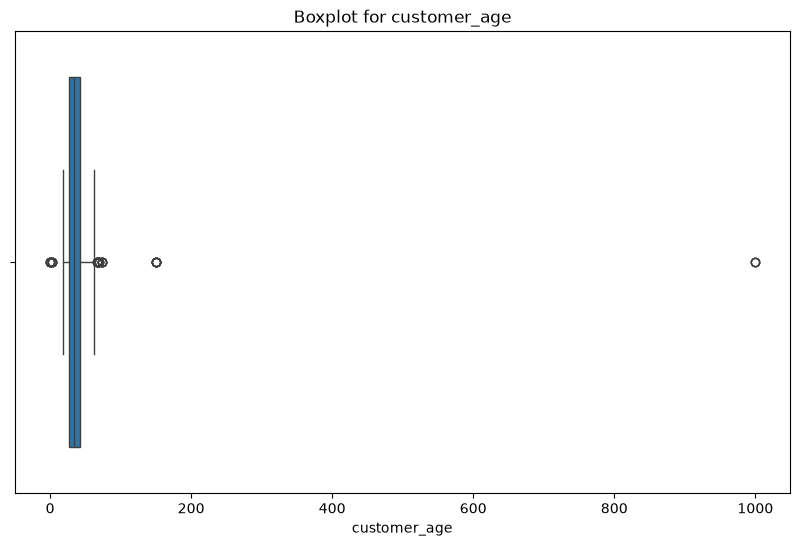

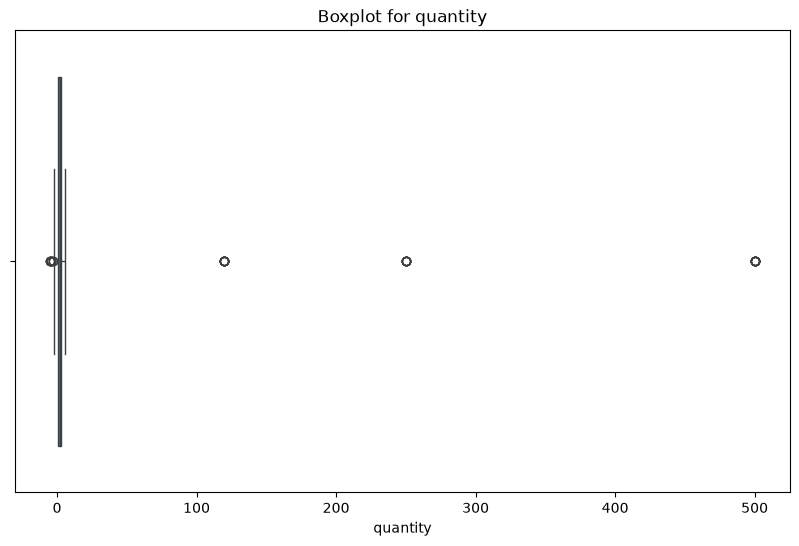

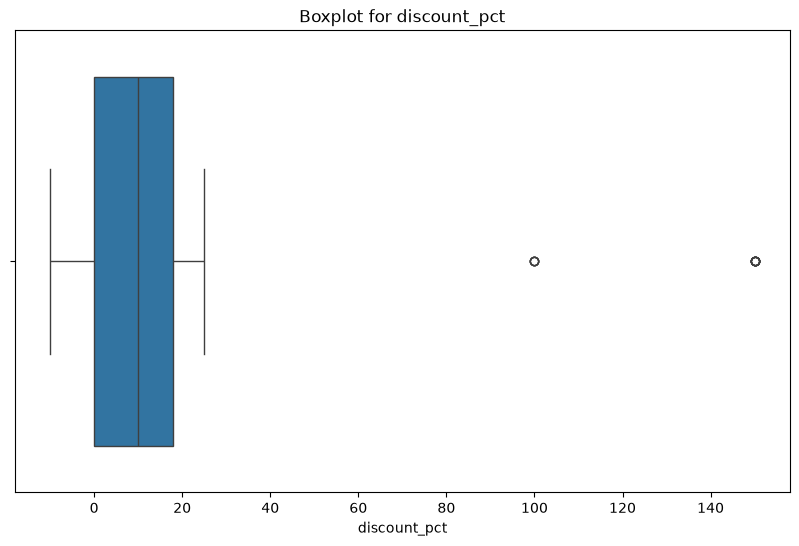

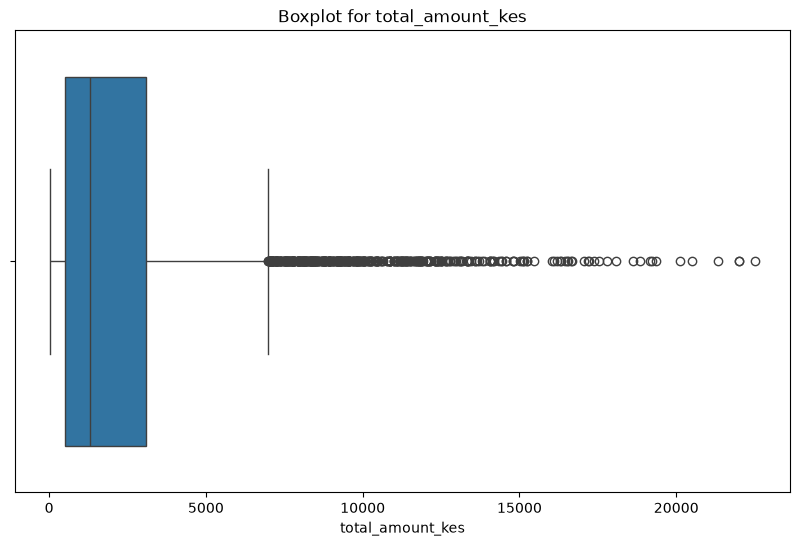

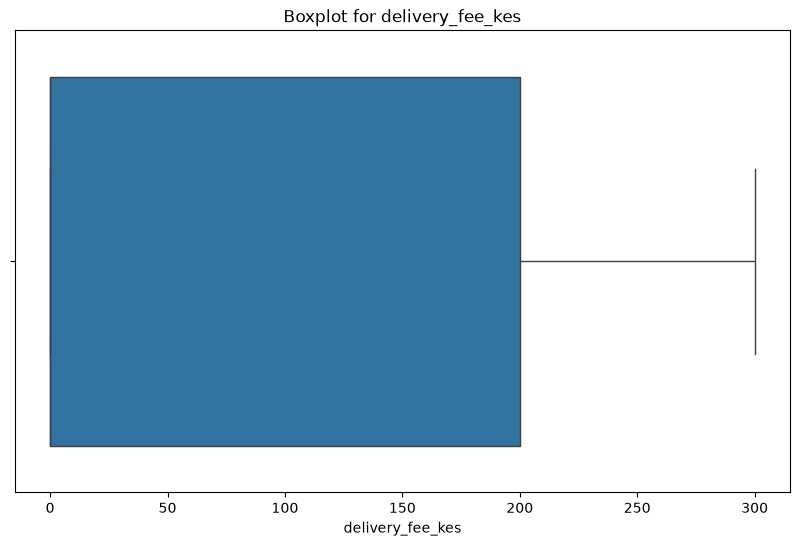

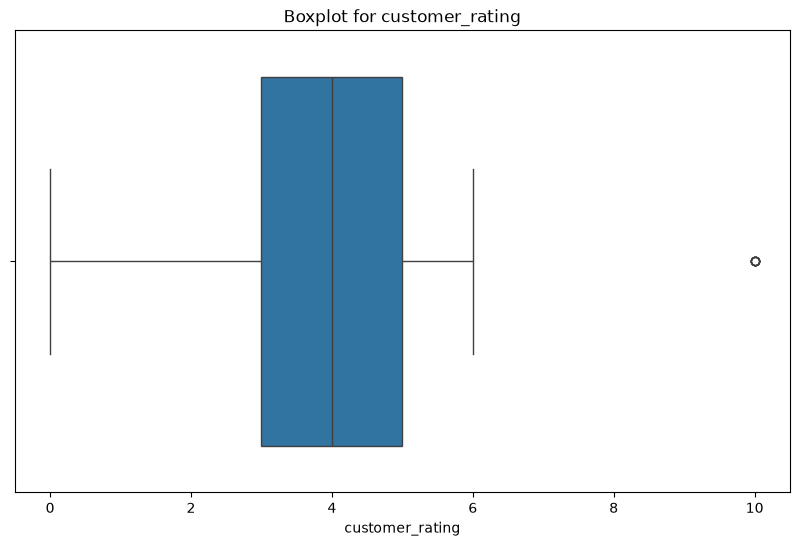

In [12]:
for col in num_cols:
    plt.figure(figsize=(10,6))
    sns.boxplot(df, x=col)
    plt.title(f"Boxplot for {col}")
    plt.show()


In [13]:
# creating a duplicate 
sales_data_copy = df.copy()

In [14]:
df['category'].unique()

<ArrowStringArray>
[          'Personal Care',           'Personal care',
              'Cold & Flu', 'Supplements & Nutrition',
              'Mum & Baby',           'PERSONAL CARE',
 'Dermatological Skincare',     'Pain & Inflammation',
      'Beauty & Skin Care',           'personal care',
         'Family Planning',            'Mum and Baby',
     'PAIN & INFLAMMATION',         'Medical Devices',
             ' Cold & Flu', 'supplements & nutrition',
     'pain & inflammation',              'cold & flu',
   'Pain and Inflammation',             'Mum & Baby ',
             'Supplements',            'Cold and Flu',
             'COLD & FLU ',              'mum & baby']
Length: 24, dtype: str

In [15]:
df["city"] = df["city"].replace({
    "NAIROBI" : "Nairobi",
    "NRB" : "Nairobi",
    "nairobi": "Nairobi",
    "Nairobi " : "Nairobi",
    "MSA" : "Mombasa",
    "mombasa" : "Mombasa",
    "kisumu" : "Kisumu"
})
df['city'].unique()

<ArrowStringArray>
['Nairobi', 'Eldoret', 'Mombasa', 'Kisumu', 'Nakuru']
Length: 5, dtype: str

In [16]:
df['city'].unique()

<ArrowStringArray>
['Nairobi', 'Eldoret', 'Mombasa', 'Kisumu', 'Nakuru']
Length: 5, dtype: str

In [17]:

# df.describe()
# This executes the function to calculate summary statistics
# (count, mean, std, min, 25%, 50%, 75%, max) for all numerical columns in your DataFrame.
df.describe()



df.describe().T
# The .T property stands for Transpose.
#  It flips the matrix on its side. Your features 
#  become rows on the left, and the statistical metrics 
#  become columns across the top.


,count,mean,std,min,25%,50%,75%,max
customer_age,5784.0,34.913900,24.547685,0.00,27.000,34.0,42.0000,999.0
quantity,6056.0,3.516843,21.401592,-5.00,1.000,2.0,3.0000,500.0
discount_pct,6028.0,9.603351,10.747402,-10.00,0.000,10.0,18.0000,150.0
total_amount_kes,6150.0,2359.303434,2881.583637,30.75,491.675,1313.0,3086.1225,22500.0
delivery_fee_kes,6150.0,77.333333,112.349548,0.00,0.000,0.0,200.0000,300.0
customer_rating,4614.0,3.857824,1.156957,0.00,3.000,4.0,5.0000,10.0


In [18]:
df['category'].unique()

<ArrowStringArray>
[          'Personal Care',           'Personal care',
              'Cold & Flu', 'Supplements & Nutrition',
              'Mum & Baby',           'PERSONAL CARE',
 'Dermatological Skincare',     'Pain & Inflammation',
      'Beauty & Skin Care',           'personal care',
         'Family Planning',            'Mum and Baby',
     'PAIN & INFLAMMATION',         'Medical Devices',
             ' Cold & Flu', 'supplements & nutrition',
     'pain & inflammation',              'cold & flu',
   'Pain and Inflammation',             'Mum & Baby ',
             'Supplements',            'Cold and Flu',
             'COLD & FLU ',              'mum & baby']
Length: 24, dtype: str

In [19]:
df['category'] = df['category'].str.capitalize().str.strip()

In [20]:
df['category'].unique()

<ArrowStringArray>
[          'Personal care',              'Cold & flu',
 'Supplements & nutrition',              'Mum & baby',
 'Dermatological skincare',     'Pain & inflammation',
      'Beauty & skin care',         'Family planning',
            'Mum and baby',         'Medical devices',
              'cold & flu',   'Pain and inflammation',
             'Supplements',            'Cold and flu']
Length: 14, dtype: str

In [21]:
df['category'] = df['category'].replace(
    {'Mum and baby' : 'Mum & baby',
     'cold & flu' : 'cold & flu',
     'Cold & flu' : 'cold & flu',
     'Cold and flu' : 'cold & flu',
     'Supplements' : 'Supplements & nutrition',
     'Pain and inflammation' : 'Pain & inflammation' 
      }
)

In [22]:
df['category'].unique()

<ArrowStringArray>
[          'Personal care',              'cold & flu',
 'Supplements & nutrition',              'Mum & baby',
 'Dermatological skincare',     'Pain & inflammation',
      'Beauty & skin care',         'Family planning',
         'Medical devices']
Length: 9, dtype: str

In [23]:
# requires prescription column
df["requires_prescription"].unique()

<ArrowStringArray>
['No', 'FALSE', '0', 'N', 'no', 'Y', 'TRUE', 'Yes', 'yes', '1']
Length: 10, dtype: str

In [24]:
df["requires_prescription"] = df["requires_prescription"].astype(str).str.strip().str.capitalize()


In [25]:
df["requires_prescription"].unique()

<ArrowStringArray>
['No', 'False', '0', 'N', 'Y', 'True', 'Yes', '1']
Length: 8, dtype: str

In [26]:
df["requires_prescription"] =df["requires_prescription"].replace(
    {
        'No' : 'False',
         '0' : 'False',
         'N' : 'False',
         'Yes' : 'True',
         '1' : 'True',
         'Y' : 'True'

    }
)

In [27]:
df["payment_method"].unique()

<ArrowStringArray>
[     'Card',    'M-Pesa', 'Insurance',         nan,      'Cash',     'mpesa',
      'CARD',      'Visa',     'MPESA',      'card',    'M-PESA',      'cash',
     'Mpesa',      'CASH']
Length: 14, dtype: str

In [28]:
df["payment_method"] = df["payment_method"].str.strip().str.capitalize()

In [29]:
df["payment_method"] = df["payment_method"].replace(
    {
        'Mpesa' : 'M-pesa',
        'Visa' : 'Card'
    }
)

In [30]:
# promocodes column(
df["promo_code"] = df["promo_code"].str.strip().str.upper()

In [31]:
df["promo_code"].unique()

<ArrowStringArray>
[        nan,   'MYDEAL5',    'WELL20',    'GLOW25',  'MYDEAL18',    'WELL15',
    'SAVE10',    'WELL25',    'GLOW18',     'GLOW5',   'HEALTH5',    'WELL10',
    'GLOW10',  'MYDEAL10',    'GLOW15',  'MYDEAL25',  'HEALTH25',     'SAVE5',
    'SAVE20', 'MYDEAL-25',    'WELL18',  'HEALTH18',  'MYDEAL20',   'GLOW-25',
    'SAVE25',    'SAVE18',   'GLOW 18',     'WELL5',    'SAVE15',  'HEALTH15',
   'GLOW-10',   'GLOW 25',   'SAVE 25',  'HEALTH20',    'GLOW20',   'WELL 18',
    'SAVE 5',    'SAVE-5',  'HEALTH10',   'WELL 25',  'HEALTH-5',   'WELL-15',
 'MYDEAL 15', 'MYDEAL-15',   'SAVE-25', 'HEALTH-15',  'MYDEAL15', 'HEALTH 18',
   'GLOW-18',  'HEALTH 5',   'SAVE-18',  'MYDEAL-5',   'WELL 20',   'GLOW-20',
 'HEALTH 15', 'MYDEAL-20',   'WELL-25',    'GLOW 5', 'MYDEAL-18',   'WELL-18',
 'HEALTH-18', 'HEALTH 20',    'GLOW-5',   'WELL-20', 'HEALTH-10',   'WELL 10',
   'GLOW-15', 'HEALTH 10',   'SAVE 18', 'MYDEAL 18',   'SAVE-15',   'SAVE-10',
 'HEALTH-25', 'MYDEAL 10',   'SAV

In [32]:
df["promo_code"] = df["promo_code"].str.replace(r'[\s-]', '', regex=True)

In [33]:
df["product_name"].unique()

<ArrowStringArray>
[           'Kotex Ultra Sanitary Pads Super 8's',
        'Nivea Rich Nourishing Body Lotion 200ml',
                    'Olbas Oil For Children 12ml',
                 'Seven Seas Cod Liver Oil 100ml',
                    'NipNap Diaper Junior 5 36's',
                 'Nivea Deo Spray Espresso 150ml',
                           'Oligocare Forte 20's',
 'La Roche-Posay Effaclar Foaming Cleanser 200ml',
               'Fay Antibacterial Wet Wipes 72's',
                           'Zefcolin Syrup 100ml',
 ...
                     '  Aptamil Baby Milk 2 800g',
          '  Panadol Advance 500mg Tablets 100's',
            'Endosan Maternity Pads Large 10's  ',
                          '  Coldcap Syrup 100ml',
                 'Centrum Men 50+ Tablets 30's  ',
    '  Uncover Argan Hydrating Moisturizer 100ml',
                       '  Epimol-E Soap Bar 100g',
        'Panadol Cold & Flu Night Tablets 24's  ',
                        'Wellbaby Liquid 150ml  ',
   'Opt

In [34]:
df["product_name"] = df["product_name"].str.strip().str.capitalize()

In [35]:
df["product_name"].unique()

<ArrowStringArray>
[           'Kotex ultra sanitary pads super 8's',
        'Nivea rich nourishing body lotion 200ml',
                    'Olbas oil for children 12ml',
                 'Seven seas cod liver oil 100ml',
                    'Nipnap diaper junior 5 36's',
                 'Nivea deo spray espresso 150ml',
                           'Oligocare forte 20's',
 'La roche-posay effaclar foaming cleanser 200ml',
               'Fay antibacterial wet wipes 72's',
                           'Zefcolin syrup 100ml',
 ...
                'Cerave blemish control gel 40ml',
                         'Dr browns silicone bib',
            'Nice & lovely baby range value pack',
    'Cinnabar body lotion geranium & lavender 1l',
  'Eucerin sun even pigment perfector fluid 50ml',
                'Cerave hydrating cleanser 473ml',
                      'Lyrica 75mg capsules 28's',
        'La roche-posay lipikar baume ap+m 200ml',
                    'Panadol extra tablets 100's',
      '

In [36]:
df.sample(10, random_state = 30)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
3487,ORD-104784,2026-08-06 17:33,NaN,CUS00054,Achieng Chege,0794096817,achieng_chege33@gmail.com,Female,48.0,Nairobi,...,06/2028,"KES 2,074",2.0,10.0,WELL10,3733.20,0.0,Cash,4.0,NaN
2764,ORD-101596,2026-03-17 10:18,2026-03-18,CUS00384,Dennis Mutiso,254752064254,dennismutiso89@gmail.com,Male,34.0,Nairobi,...,05/2027,1577.0,1.0,20.0,MYDEAL20,1261.60,300.0,Card,5.0,
4821,ORD-102493,2026-04-28 11:46,2026-04-28,CUS01457,Muthoni Hassan,0795 031 174,muthonihassan29@students.uonbi.ac.ke,Female,31.0,Nairobi,...,12/2026,201.0,1.0,0.0,NaN,201.00,250.0,M-pesa,4.0,WORKS WELL FOR MY FAMILY
3514,ORD-104320,2026-07-18 19:32,NaN,CUS00352,Njeri Omondi,+254747263214,njeri_omondi27@gmail.com,Female,NaN,Kisumu,...,01/2028,110.0,1.0,18.0,WELL18,90.20,0.0,M-pesa,NaN,NaN
5519,ORD-102630,2026-05-06 08:19,2026-05-06,CUS00181,Njoroge Mwangi,0758315140,njoroge.mwangi87@students.uonbi.ac.ke,Male,28.0,Nairobi,...,05/2027,4105.0,1.0,10.0,GLOW10,3694.50,0.0,Card,4.0,Easy to pay with M-Pesa
5698,ORD-100090,2026-01-05 10:49,NaN,CUS01348,Omondi Otieno,0717 136 055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,05/2027,NaN,3.0,15.0,SAVE15,311.10,0.0,Cash,5.0,NaN
2142,ORD-104404,2026-07-22 12:19,2026-07-24,CUS01242,Atieno Wekesa,0191 251 714,atieno_wekesa@gmail.com,Female,27.0,Eldoret,...,08/2027,6382.0,1.0,18.0,MYDEAL18,5233.24,0.0,Insurance,5.0,Delivered to my office in Westlands within hours
5772,ORD-102377,2026-04-22 17:59,2026-04-23,CUS01045,Achieng Mohamed,793860777,achieng_mohamed@gmail.com,Female,37.0,Nairobi,...,05/2027,1735.0,2.0,0.0,NaN,3470.00,0.0,M-pesa,5.0,NaN
813,ORD-102428,2026-04-25 08:19,NaN,CUS00359,Achieng Odhiambo,0749800319,achieng_odhiambo2@outlook.com,Female,20.0,Nairobi,...,06/2028,1991.0,2.0,0.0,NaN,3982.00,0.0,M-pesa,10.0,NaN
2498,ORD-104358,2026-07-20 17:13,NaN,CUS01030,AKINYI KIPTOO,254765462927,AKINYI.KIPTOO81@GMAIL.COM,Female,19.0,Kisumu,...,08/2028,548.0,5.0,18.0,MYDEAL18,2246.80,0.0,M-pesa,NaN,NaN


In [37]:
df["customer_name"] = df["customer_name"].str.strip().str.title()


In [38]:
df['customer_name'] = df['customer_name'].str.strip().str.replace(r'\s+', ' ', regex=True).str.title()

In [39]:
df.head(10)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,expiry_date,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review
0,ORD-101260,2026-03-01 13:32,NaN,CUS00473,Njeri Onyango,0799 297 864,njerionyango@gmail.com,Female,39.0,Nairobi,...,10/2026,134.0,1.0,0.0,NaN,134.0,0.0,Card,4.0,NaN
1,ORD-102354,2026-04-21 15:37,NaN,CUS00404,Mercy Kamau,0746-061-372,mercy.kamau@icloud.com,Female,45.0,Eldoret,...,01/2028,373.0,1.0,0.0,NaN,373.0,0.0,M-pesa,3.0,NaN
2,ORD-105391,2026-09-01 12:30,2026-09-01,CUS01110,Ochieng Mutiso,730127413,ochieng_mutiso@gmail.com,Male,49.0,Nairobi,...,03/2029,1336.0,3.0,0.0,NaN,4008.0,0.0,M-pesa,4.0,NaN
3,ORD-100305,2026-01-15 12:47,NaN,CUS01757,Barasa Wanjala,0763293198,barasa_wanjala79@outlook.com,Male,32.0,Mombasa,...,07/2027,1045.0,4.0,5.0,MYDEAL5,3971.0,0.0,M-pesa,4.0,NaN
4,ORD-103519,2026-06-13 18:13,2026-06-13,CUS01348,Omondi Otieno,+254717136055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,05/2028,985.0,1.0,20.0,WELL20,788.0,150.0,M-pesa,3.0,"Fine, nothing special"
5,ORD-103590,2026-06-16 19:20,NaN,CUS01683,Atieno Maina,+254725565732,NaN,Female,61.0,Eldoret,...,10/2027,373.0,2.0,0.0,NaN,746.0,0.0,M-pesa,NaN,NaN
6,ORD-104051,2026-07-07 19:04,2026-07-12,CUS00324,Wambui Otieno,0764 206 790,wambui_otieno48@gmail.com,Female,52.0,Kisumu,...,11/2028,777.0,2.0,25.0,GLOW25,1165.5,150.0,M-pesa,3.0,"Fine, nothing special"
7,ORD-104798,2026-08-07 17:15,2026-08-08,CUS00424,Muthoni Kilonzo,+254739443335,muthoni.kilonzo@gmail.com,Female,18.0,Nairobi,...,09/2028,1328.0,1.0,0.0,NaN,1328.0,250.0,M-pesa,4.0,"POA SANA, PACKAGING WAS NEAT"
8,ORD-105559,2026-09-09 18:40,NaN,CUS01312,Faith Ruto,+254796480456,faith_ruto47@gmail.com,Female,55.0,Mombasa,...,04/2027,2821.0,1.0,0.0,NaN,2821.0,0.0,Card,NaN,NaN
9,ORD-100246,2026-01-12 16:18,NaN,CUS01666,Mutua Achieng,0768 838 383,mutuaachieng@gmail.com,Male,33.0,Nairobi,...,04/2028,181.0,3.0,0.0,NaN,543.0,0.0,M-pesa,NaN,NaN


In [40]:
df["customer_review"] = (
    df["customer_review"]
    .str.strip()
    .str.capitalize()
    .str.replace("-", "None")
    .replace("", "None")
    .fillna("None")
)

In [41]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6150 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               6150 non-null   str    
 1   order_date             6150 non-null   str    
 2   delivery_date          2836 non-null   str    
 3   customer_id            6150 non-null   str    
 4   customer_name          6028 non-null   str    
 5   customer_phone         6025 non-null   str    
 6   customer_email         5963 non-null   str    
 7   customer_gender        5963 non-null   str    
 8   customer_age           5784 non-null   float64
 9   city                   6150 non-null   str    
 10  branch                 6088 non-null   str    
 11  channel                6150 non-null   str    
 12  product_id             6150 non-null   str    
 13  product_name           6150 non-null   str    
 14  category               6150 non-null   str    
 15  requires_prescr

In [42]:
df["order_id"].duplicated().sum()

np.int64(150)

In [43]:
df.duplicated().sum()

np.int64(120)

In [44]:
df = df.drop_duplicates()

In [45]:
df.info()

<class 'pandas.DataFrame'>
Index: 6030 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   order_id               6030 non-null   str    
 1   order_date             6030 non-null   str    
 2   delivery_date          2790 non-null   str    
 3   customer_id            6030 non-null   str    
 4   customer_name          5910 non-null   str    
 5   customer_phone         5909 non-null   str    
 6   customer_email         5849 non-null   str    
 7   customer_gender        5848 non-null   str    
 8   customer_age           5671 non-null   float64
 9   city                   6030 non-null   str    
 10  branch                 5970 non-null   str    
 11  channel                6030 non-null   str    
 12  product_id             6030 non-null   str    
 13  product_name           6030 non-null   str    
 14  category               6030 non-null   str    
 15  requires_prescriptio

In [46]:
df["order_date"].info

<bound method Series.info of 0       2026-03-01 13:32
1       2026-04-21 15:37
2       2026-09-01 12:30
3       2026-01-15 12:47
4       2026-06-13 18:13
              ...       
6145    2026-09-16 13:55
6146    2026-05-01 10:09
6147    2026-01-25 17:45
6148    2026-02-27 17:51
6149    2026-07-16 14:40
Name: order_date, Length: 6030, dtype: str>

In [47]:
df["order_date"] = pd.to_datetime(df["order_date"], format ="mixed", dayfirst=True, errors="coerce")

In [48]:
df['customer_phone'].head()

0     0799 297 864
1     0746-061-372
2        730127413
3       0763293198
4    +254717136055
Name: customer_phone, dtype: str

In [49]:
df.info()

<class 'pandas.DataFrame'>
Index: 6030 entries, 0 to 6149
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               6030 non-null   str           
 1   order_date             6030 non-null   datetime64[us]
 2   delivery_date          2790 non-null   str           
 3   customer_id            6030 non-null   str           
 4   customer_name          5910 non-null   str           
 5   customer_phone         5909 non-null   str           
 6   customer_email         5849 non-null   str           
 7   customer_gender        5848 non-null   str           
 8   customer_age           5671 non-null   float64       
 9   city                   6030 non-null   str           
 10  branch                 5970 non-null   str           
 11  channel                6030 non-null   str           
 12  product_id             6030 non-null   str           
 13  product_name       

In [50]:
# 1. Base Cleanup: convert to string, strip spaces, remove trailing decimals & non-digits
df['customer_phone'] = df['customer_phone'].astype(str).str.strip()
df['customer_phone'] = df['customer_phone'].str.replace(r'\.0$', '', regex=True)
df['customer_phone'] = df['customer_phone'].str.replace(r'\D', '', regex=True)

# 2. If it starts with 2547... or 2541... (12 digits), swap the 254 for 0
df['customer_phone'] = df['customer_phone'].str.replace(r'^254(7|1)', r'0\1', regex=True)

# 3. If it is exactly 9 digits long (e.g., 712345678), pad it with a leading 0
mask_9digits = df['customer_phone'].str.len() == 9
df.loc[mask_9digits, 'customer_phone'] = '0' + df.loc[mask_9digits, 'customer_phone']


In [51]:
df["customer_phone"].unique()

<ArrowStringArray>
['0799297864', '0746061372', '0730127413', '0763293198', '0717136055',
 '0725565732', '0764206790', '0739443335', '0796480456', '0768838383',
 ...
       '0759', '0785239135', '0751421173', '0774822842', '0794398858',
 '0793743715', '0729180612', '0744484413',     '078754', '0711951980']
Length: 1756, dtype: str

In [52]:
# flag for numberes that are greater than 10
df["valid_phone"] = np.where(df["customer_phone"].str.len() == 10, 'valid', 'invalid')

In [53]:
df.head(50)

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,valid_phone
0,ORD-101260,2026-01-03 13:32:00,NaN,CUS00473,Njeri Onyango,0799297864,njerionyango@gmail.com,Female,39.0,Nairobi,...,134.0,1.0,0.0,NaN,134.00,0.0,Card,4.0,None,valid
1,ORD-102354,2026-04-21 15:37:00,NaN,CUS00404,Mercy Kamau,0746061372,mercy.kamau@icloud.com,Female,45.0,Eldoret,...,373.0,1.0,0.0,NaN,373.00,0.0,M-pesa,3.0,None,valid
2,ORD-105391,2026-01-09 12:30:00,2026-09-01,CUS01110,Ochieng Mutiso,0730127413,ochieng_mutiso@gmail.com,Male,49.0,Nairobi,...,1336.0,3.0,0.0,NaN,4008.00,0.0,M-pesa,4.0,None,valid
3,ORD-100305,2026-01-15 12:47:00,NaN,CUS01757,Barasa Wanjala,0763293198,barasa_wanjala79@outlook.com,Male,32.0,Mombasa,...,1045.0,4.0,5.0,MYDEAL5,3971.00,0.0,M-pesa,4.0,None,valid
4,ORD-103519,2026-06-13 18:13:00,2026-06-13,CUS01348,Omondi Otieno,0717136055,omondi_otieno@outlook.com,Male,30.0,Nairobi,...,985.0,1.0,20.0,WELL20,788.00,150.0,M-pesa,3.0,"Fine, nothing special",valid
5,ORD-103590,2026-06-16 19:20:00,NaN,CUS01683,Atieno Maina,0725565732,NaN,Female,61.0,Eldoret,...,373.0,2.0,0.0,NaN,746.00,0.0,M-pesa,NaN,None,valid
6,ORD-104051,2026-07-07 19:04:00,2026-07-12,CUS00324,Wambui Otieno,0764206790,wambui_otieno48@gmail.com,Female,52.0,Kisumu,...,777.0,2.0,25.0,GLOW25,1165.50,150.0,M-pesa,3.0,"Fine, nothing special",valid
7,ORD-104798,2026-07-08 17:15:00,2026-08-08,CUS00424,Muthoni Kilonzo,0739443335,muthoni.kilonzo@gmail.com,Female,18.0,Nairobi,...,1328.0,1.0,0.0,NaN,1328.00,250.0,M-pesa,4.0,"Poa sana, packaging was neat",valid
8,ORD-105559,2026-09-09 18:40:00,NaN,CUS01312,Faith Ruto,0796480456,faith_ruto47@gmail.com,Female,55.0,Mombasa,...,2821.0,1.0,0.0,NaN,2821.00,0.0,Card,NaN,None,valid
9,ORD-100246,2026-12-01 16:18:00,NaN,CUS01666,Mutua Achieng,0768838383,mutuaachieng@gmail.com,Male,33.0,Nairobi,...,181.0,3.0,0.0,NaN,543.00,0.0,M-pesa,NaN,None,valid


In [54]:
df["valid_phone"].value_counts()

valid_phone
valid      5872
invalid     158
Name: count, dtype: int64

In [55]:
df["customer_email"] = df["customer_email"].str.strip().str.lower()

In [56]:
# cleaning the customer age column
# calculating the inter_quartile range  IQR
first_quartile = df["customer_age"].quantile(.25)
second_quartile = df["customer_age"].quantile(.5)
third_quartile = df["customer_age"].quantile(.75)

# calculate the iqr
iqr = third_quartile - first_quartile

# calculate the max and minimum age values 
max_age = third_quartile + (1.5 * iqr) 
min_age = first_quartile - (1.5 * iqr)

print(min_age)
print(max_age)

4.5
64.5


In [57]:
# filter age to display ages above the maximum age 
filtered_age = df[df["customer_age"] > 64.5]
filtered_age


,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,valid_phone
72,ORD-102173,2026-04-13 00:00:00,2026-04-14,CUS00852,Wairimu Otieno,0190610028,wairimuotieno@gmail.com,Female,68.0,Nairobi,...,2235.0,4.0,10.0,SAVE10,8046.00,0.0,M-pesa,4.0,None,valid
242,ORD-102609,2026-04-05 14:46:00,2026-05-05,CUS00439,Wanjiku Achieng,0747691493,wanjiku.achieng@gmail.com,Female,150.0,Nairobi,...,1870.0,2.0,0.0,NaN,3740.00,0.0,Insurance,3.0,None,valid
291,ORD-101586,2026-03-16 15:31:00,NaN,CUS00829,Kiprono Mohamed,0780101378,kipronomohamed@gmail.com,Male,999.0,Nairobi,...,"KES 2,152",5.0,15.0,WELL15,9146.00,0.0,M-pesa,5.0,Easy to pay with mNonepesa,valid
401,ORD-101051,2026-02-19 17:14:00,2026-02-21,CUS00852,Wairimu Otieno,0190610028,NaN,Female,68.0,Nairobi,...,1957.0,3.0,10.0,MYDEAL10,5283.90,0.0,Insurance,4.0,None,valid
421,ORD-100359,2026-01-18 10:05:00,2026-01-23,CUS00196,Mercy Wekesa,0731495577,mercywekesa@gmail.com,Female,999.0,Kisumu,...,1205.0,2.0,18.0,SAVE18,1976.20,250.0,M-pesa,1.0,None,valid
461,ORD-105778,2026-09-19 16:48:00,NaN,CUS01795,Samuel Otieno,0199819736,samuel_otieno@gmail.com,Male,150.0,Mombasa,...,394.0,1.0,0.0,NaN,394.00,0.0,M-pesa,4.0,None,valid
521,ORD-103199,2026-01-06 18:21:00,NaN,CUS00852,Wairimu Otieno,0190610028,wairimuotieno@gmail.com,Female,68.0,Nairobi,...,144.0,1.0,20.0,WELL20,115.20,0.0,M-pesa,5.0,Good price compared to other shops,valid
1148,ORD-105906,2026-09-26 13:10:00,NaN,CUS00270,Purity Kimani,0114553432,purity.kimani37@gmail.com,Female,999.0,Nairobi,...,334.0,5.0,0.0,NaN,1670.00,200.0,Card,2.0,"Poor customer service, no refund yet",valid
1274,ORD-104177,2026-07-13 09:09:00,NaN,CUS00012,Wairimu Onyango,0748799613,wairimu.onyango95@gmail.com,Female,74.0,Nairobi,...,2996.0,1.0,15.0,WELL15,2546.60,0.0,M-pesa,5.0,None,valid
1556,ORD-103412,2026-09-06 14:11:00,NaN,CUS00012,Wairimu Onyango,0748799613,wairimu.onyango95@gmail.com,Female,74.0,Nairobi,...,2348.0,5.0,0.0,NaN,11740.00,0.0,Insurance,3.0,None,valid


In [58]:
upper_threshold = 100
df = df[df["customer_age"] <= upper_threshold]

In [59]:
print(len(df))
print(len(filtered_age))
df.shape

5661
28


(5661, 27)

In [60]:
df.duplicated().sum()

np.int64(0)

In [61]:
df.shape

(5661, 27)

In [62]:
df.info()

<class 'pandas.DataFrame'>
Index: 5661 entries, 0 to 6149
Data columns (total 27 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   order_id               5661 non-null   str           
 1   order_date             5661 non-null   datetime64[us]
 2   delivery_date          2620 non-null   str           
 3   customer_id            5661 non-null   str           
 4   customer_name          5550 non-null   str           
 5   customer_phone         5549 non-null   str           
 6   customer_email         5489 non-null   str           
 7   customer_gender        5487 non-null   str           
 8   customer_age           5661 non-null   float64       
 9   city                   5661 non-null   str           
 10  branch                 5603 non-null   str           
 11  channel                5661 non-null   str           
 12  product_id             5661 non-null   str           
 13  product_name       

In [63]:
df["unit_price_kes"] = df["unit_price_kes"].astype(str).str.replace(r'[^0-9.]', '', regex=True).astype(float)

In [64]:
df["unit_price_kes"].info()

<class 'pandas.Series'>
Index: 5661 entries, 0 to 6149
Series name: unit_price_kes
Non-Null Count  Dtype  
--------------  -----  
5543 non-null   float64
dtypes: float64(1)
memory usage: 88.5 KB


In [65]:
df["quantity"].min()

np.float64(-5.0)

In [67]:
quantity_subset_zero = df[df["quantity"] < 0]
quantity_subset_zero

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,valid_phone
169,ORD-102751,2026-10-05 19:43:00,NaN,CUS00212,Nekesa Ali,0795477839,nekesaali19@gmail.com,Female,31.0,Nairobi,...,4635.0,-1.0,5.0,HEALTH5,4403.25,0.0,M-pesa,NaN,None,valid
485,ORD-104488,2026-07-25 16:29:00,2026-07-27,CUS01386,Sharon Cheruiyot,0764502212,sharon.cheruiyot27@gmail.com,Female,18.0,Nairobi,...,686.0,-1.0,0.0,NaN,686.00,300.0,Card,5.0,None,valid
522,ORD-100019,2026-01-01 19:58:00,NaN,CUS00607,Otieno Odhiambo,0764482292,otienoodhiambo73@yahoo.com,Male,35.0,Nairobi,...,359.0,-1.0,0.0,NaN,359.00,0.0,M-pesa,4.0,Product exactly as described,valid
1209,ORD-102222,2026-04-15 16:10:00,2026-04-20,CUS01417,Mwangi Odhiambo,0713977753,NaN,Male,61.0,Mombasa,...,1097.0,-3.0,25.0,WELL25,2468.25,150.0,M-pesa,3.0,None,valid
1219,ORD-101680,2026-03-21 13:21:00,NaN,CUS00914,Esther Cheruiyot,0723009527,esthercheruiyot16@gmail.com,Female,39.0,Nairobi,...,161.0,-2.0,0.0,NaN,322.00,0.0,Card,NaN,None,valid
1591,ORD-101553,2026-03-14 20:47:00,2026-03-14,CUS00411,Kipchoge Wairimu,0745021848,kipchogewairimu@safaricom.co.ke,Male,40.0,Nairobi,...,2440.0,-1.0,0.0,NaN,2440.00,300.0,Insurance,4.0,Works well for my family,valid
1716,ORD-102766,2026-11-05 18:53:00,2026-05-12,CUS00061,Allan Kamau,0760095949,allan_kamau26@outlook.com,Male,30.0,Nairobi,...,389.0,-4.0,0.0,NaN,1556.00,250.0,Cash,4.0,None,valid
1751,ORD-105930,2026-09-27 13:36:00,NaN,CUS01323,Ian Maina,0757428121,ianmaina86@gmail.com,Male,32.0,Nairobi,...,518.0,-2.0,10.0,GLOW10,932.40,0.0,M-pesa,5.0,Works well for my family,valid
1846,ORD-104683,2026-02-08 20:29:00,2026-08-03,CUS00226,Wafula Ndungu,0721425757,wafulandungu13@gmail.com,Male,46.0,Nairobi,...,986.0,-1.0,10.0,SAVE10,887.40,200.0,M-pesa,3.0,Rider called many times to find me,valid
1854,ORD-103225,2026-02-06 16:00:00,NaN,CUS00853,Barasa Kamau,0114313954,barasa_kamau90@gmail.com,Male,36.0,Nairobi,...,302.0,-5.0,10.0,WELL10,1359.00,0.0,M-pesa,5.0,None,valid


In [ ]:
# cleaning the quantity column
df["quantity"] = df["quantity"].abs()


In [75]:
# cleaning the discount_pct column
discount_subset = df[(df["discount_pct"] < 0) | (df["discount_pct"] > 30)]
discount_subset

,order_id,order_date,delivery_date,customer_id,customer_name,customer_phone,customer_email,customer_gender,customer_age,city,...,unit_price_kes,quantity,discount_pct,promo_code,total_amount_kes,delivery_fee_kes,payment_method,customer_rating,customer_review,valid_phone
587,ORD-101739,2026-03-23 19:26:00,NaN,CUS00331,Wafula Kilonzo,0792469259,wafulakilonzo@yahoo.com,Male,22.0,Nairobi,...,4511.0,5.0,100.0,SAVE15,19171.75,0.0,M-pesa,5.0,None,valid
641,ORD-103119,2026-05-29 13:48:00,2026-05-30,CUS00717,Brian Kamau,0718231574,brian.kamau@icloud.com,Male,52.0,Nairobi,...,1028.0,3.0,100.0,HEALTH20,2467.20,300.0,M-pesa,5.0,Easy to pay with mNonepesa,valid
694,ORD-105128,2026-08-20 18:58:00,NaN,CUS01580,Nekesa Otieno,0788895085,nekesaotieno@gmail.com,Female,40.0,Kisumu,...,878.0,2.0,150.0,NaN,1756.00,0.0,M-pesa,NaN,None,valid
1146,ORD-101402,2026-07-03 17:27:00,NaN,CUS00824,NaN,0789344265,NaN,Female,31.0,Eldoret,...,973.0,2.0,150.0,NaN,1946.00,0.0,M-pesa,5.0,Easy to pay with mNonepesa,valid
1248,ORD-101498,2026-12-03 08:10:00,NaN,CUS00837,Brian Wairimu,0718318464,brian.wairimu60@icloud.com,Male,37.0,Mombasa,...,4046.0,5.0,-10.0,GLOW5,19218.50,0.0,NaN,2.0,"Poor customer service, no refund yet",valid
1418,ORD-100048,2026-03-01 00:00:00,2026-01-05,CUS00962,Nekesa Maina,0776782283,nekesa.maina35@gmail.com,Female,40.0,Nakuru,...,125.0,3.0,-10.0,NaN,375.00,300.0,Insurance,5.0,"Genuine product, will buy again",valid
1603,ORD-104963,2026-08-14 17:06:00,NaN,CUS00602,Atieno Ruto,0770355096,NaN,Female,23.0,Eldoret,...,320.0,4.0,-10.0,WELL18,1049.60,0.0,M-pesa,4.0,None,valid
2053,ORD-100259,2026-01-13 09:33:00,NaN,CUS01668,Esther Ruto,0721286343,esther_ruto@gmail.com,Female,30.0,Nakuru,...,1671.0,3.0,150.0,NaN,5013.00,0.0,Card,NaN,None,valid
2176,ORD-103914,2026-01-07 17:52:00,NaN,CUS00265,Mwangi Nduta,0733129248,mwangi_nduta@gmail.com,Male,38.0,Nairobi,...,210.0,1.0,150.0,GLOW5,199.50,0.0,M-pesa,NaN,None,valid
2204,ORD-103496,2026-12-06 19:08:00,2026-06-13,CUS00917,Nyambura Omondi,0788979384,nyamburaomondi26@students.uonbi.ac.ke,Female,49.0,Nairobi,...,1365.0,2.0,-10.0,MYDEAL25,2047.50,300.0,M-pesa,4.0,None,valid


In [76]:
promo_code_subset = df["promo_code"].str.replace(r'\D', "", regex=True).astype(float)
promo_code_subset.head()

0     NaN
1     NaN
2     NaN
3     5.0
4    20.0
Name: promo_code, dtype: float64

In [77]:
df["promo_code_subset"] = df["promo_code"].str.replace(r'\D', "", regex=True).astype(float)
df[["promo_code_subset", "discount_pct"]]

,promo_code_subset,discount_pct
0,NaN,0.0
1,NaN,0.0
2,NaN,0.0
3,5.0,5.0
4,20.0,20.0
...,...,...
6145,NaN,0.0
6146,15.0,15.0
6147,18.0,18.0
6148,NaN,0.0


In [78]:
df.isna().sum()

order_id                    0
order_date                  0
delivery_date            3041
customer_id                 0
customer_name             111
customer_phone            112
customer_email            172
customer_gender           174
customer_age                0
city                        0
branch                     58
channel                     0
product_id                  0
product_name                0
category                    0
requires_prescription       0
expiry_date                 0
unit_price_kes            118
quantity                   85
discount_pct              114
promo_code               2242
total_amount_kes            0
delivery_fee_kes            0
payment_method            142
customer_rating          1407
customer_review             0
valid_phone                 0
promo_code_subset        2242
dtype: int64